# MathVision AI — Kaggle GPU Training (TrOCR fine-tuning)

**Kaggle settings (right sidebar) before running:**
1. **Accelerator:** GPU T4 x2 (ya P100) — **Internet: ON** (HuggingFace se `trocr-large-handwritten` download hota hai)
2. **Add Data (3 inputs):**
   - Tumhara project zip dataset (`mathvision-ai-complete.zip` upload karke banaya hua dataset)
   - `rtatman/handwritten-mathematical-expressions`
   - `sagyamthapa/handwritten-math-symbols`
3. Pehli baar `SMOKE_TEST = True` rakho (5-15 min). Sab cells error-free chal jaye tab `False` karke **Save Version -> Save & Run All (Commit)** se full training chalao.

Output: `/kaggle/working/trocr_finetuned.zip` (model) + `model_card.json` (real metrics).

In [5]:
# ============ CONFIG (sirf yahin change karo) ============
SMOKE_TEST = False          # True = tiny run to validate pipeline + GPU memory. Full run ke liye False.
FAST_MODE = False          # True = trocr-base-handwritten (2-3x faster, thoda kam accurate)
EPOCHS = 4                 # spec: 5
LR = 5e-5                  # spec: 5e-5
EFFECTIVE_BATCH = 8        # spec: 8 (per-GPU 4 x grad-accum / GPUs se banta hai)
PER_DEVICE_BATCH = 2       # pehle 4 tha (T4 x2: 2 x 2 GPUs x accum 2 = effective 8)
SYMBOLS_PER_CLASS = 150    # 82 classes x 150 ~ 12k; poore 82k lene se expressions dab jate hain + time 4x
FLIP_Y = False             # preview me CROHME images ulte dikhein to True karo
EVAL_SUBSET = 500          # har epoch ke end pe itne val samples pe CER
TIME_BUDGET_HOURS = 9.5   # Kaggle session limit 12h; isse pehle gracefully stop + save
SEED = 42
HF_REPO = ""               # optional: "username/trocr-finetuned-math" (Kaggle Secret HF_TOKEN chahiye)

BASE_MODEL = "microsoft/trocr-base-handwritten" if FAST_MODE else "microsoft/trocr-large-handwritten"
print("SMOKE_TEST:", SMOKE_TEST, "| BASE_MODEL:", BASE_MODEL)

SMOKE_TEST: False | BASE_MODEL: microsoft/trocr-large-handwritten


In [6]:
import os, sys, subprocess, json, time, random, shutil, math
from pathlib import Path

os.environ["CUDA_VISIBLE_DEVICES"] = "0" 

# transformers v5 me TrOCR tokenizer load nahi hota -> v4 pin (import SE PEHLE install zaroori)
assert "transformers" not in sys.modules, (
    "transformers pehle se import ho chuka hai -> Run > 'Restart & clear cell outputs' karo, phir Run All")
r = subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "python-dotenv", "sympy", "sentencepiece", "protobuf",
                    "transformers>=4.46,<5"], capture_output=True, text=True)
if r.returncode != 0:
    print("pip STDERR:", r.stderr[-1500:])

import torch, transformers
print("torch", torch.__version__, "| transformers", transformers.__version__)
print("CUDA:", torch.cuda.is_available(), "| GPUs:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    p = torch.cuda.get_device_properties(i)
    print(f"  GPU{i}: {p.name} {p.total_memory/1e9:.1f} GB")
assert torch.cuda.is_available(), "GPU OFF hai — Settings > Accelerator me GPU select karo"
major, minor = (int(x) for x in transformers.__version__.split(".")[:2])
assert major == 4 and minor >= 41, f"transformers {transformers.__version__} mila, 4.x chahiye -> restart karke Run All"

torch 2.11.0+cu128 | transformers 4.57.6
CUDA: True | GPUs: 1
  GPU0: Tesla T4 15.6 GB


In [7]:
from collections import deque

KAGGLE_INPUT = Path(os.environ.get("KAGGLE_INPUT_DIR", "/kaggle/input"))
WORK = Path(os.environ.get("KAGGLE_WORKING_DIR", "/kaggle/working"))

def _subdirs(d: Path):
    try:
        with os.scandir(d) as it:
            return sorted(Path(e.path) for e in it if e.is_dir())
    except OSError:
        return []

def iter_dirs(root: Path, max_depth: int = 4):
    """Breadth-first directory walk (dirs only, scandir = no per-file stat) with depth limit."""
    queue = deque([(root, 0)])
    while queue:
        d, depth = queue.popleft()
        yield d
        if depth < max_depth:
            queue.extend((c, depth + 1) for c in _subdirs(d))

IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp", ".gif"}
def has_images(d: Path) -> bool:
    try:
        with os.scandir(d) as it:
            return any(e.is_file() and Path(e.name).suffix.lower() in IMG_EXT for e in it)
    except OSError:
        return False

def print_tree(root: Path, max_depth: int = 3, max_dirs: int = 40):
    """Diagnostic: folder structure + file counts + sample file names."""
    shown = 0
    for d in iter_dirs(root, max_depth):
        try:
            with os.scandir(d) as it:
                entries = list(it)
        except OSError:
            continue
        files = [e.name for e in entries if e.is_file()]
        print(f"{d}  | subdirs={sum(e.is_dir() for e in entries)} files={len(files)} sample={files[:3]}")
        shown += 1
        if shown >= max_dirs:
            print("..."); break

# ---- 1) project code ----
project_src = next((d for d in iter_dirs(KAGGLE_INPUT, 4) if (d / "src" / "config.py").exists()), None)
assert project_src, "Project dataset nahi mila — zip ko Kaggle Dataset ke roop me upload karke Add Data karo"
PROJECT = WORK / "mathvision-ai"
shutil.copytree(project_src, PROJECT, dirs_exist_ok=True)
os.chdir(PROJECT)
sys.path.insert(0, str(PROJECT))
print("Project:", project_src, "->", PROJECT)

# ---- 2) datasets ----
def find_dataset(*keywords: str):
    for d in iter_dirs(KAGGLE_INPUT, 4):
        name = d.name.lower()
        if all(k in name for k in keywords):
            return d
    return None

CROHME_ROOT = find_dataset("handwritten", "expression")
SYMBOLS_ROOT = find_dataset("handwritten", "symbol")
print("CROHME_ROOT :", CROHME_ROOT)
print("SYMBOLS_ROOT:", SYMBOLS_ROOT)
assert CROHME_ROOT, "CROHME dataset add nahi kiya (rtatman/handwritten-mathematical-expressions)"
assert SYMBOLS_ROOT, "Symbols dataset add nahi kiya (sagyamthapa/handwritten-math-symbols)"

def find_class_root(root: Path, min_classes: int = 10, max_depth: int = 8):
    """Folder-per-class layout: pehla folder jiske >= min_classes subfolders me images hon."""
    for d in iter_dirs(root, max_depth):
        subs = _subdirs(d)
        if len(subs) >= min_classes and sum(has_images(c) for c in subs[:min_classes * 2]) >= min_classes:
            return d
    return None

SYMBOLS_CLASS_ROOT = find_class_root(SYMBOLS_ROOT)
print("SYMBOLS_CLASS_ROOT:", SYMBOLS_CLASS_ROOT)
if not SYMBOLS_CLASS_ROOT:
    print("\nSymbols dataset ka structure (ye output mujhe paste karo):")
    print_tree(SYMBOLS_ROOT, max_depth=4)
    raise AssertionError("Symbol class folders nahi mile — upar ka structure dekho")

n_inkml = sum(1 for _ in CROHME_ROOT.rglob("*.inkml"))
print("InkML files found:", n_inkml)
if n_inkml == 0:
    print("\nCROHME dataset ka structure (ye output mujhe paste karo):")
    print_tree(CROHME_ROOT, max_depth=3)
    raise AssertionError("Is dataset me .inkml nahi mili — upar ka structure dekho")

Project: /kaggle/input/datasets/narendrakalam/mathvision-ai-code/mathvision-ai -> /kaggle/working/mathvision-ai
CROHME_ROOT : /kaggle/input/datasets/rtatman/handwritten-mathematical-expressions
SYMBOLS_ROOT: /kaggle/input/datasets/sagyamthapa/handwritten-math-symbols
SYMBOLS_CLASS_ROOT: /kaggle/input/datasets/sagyamthapa/handwritten-math-symbols/dataset
InkML files found: 24203


In [8]:
import scripts.prepare_datasets as prep
from src.config import settings

# Kaggle-specific: default folder-name list me kuch na mile to poore dataset me recursive dhoondo
if not prep.discover_inkml_files(CROHME_ROOT):
    print("Default CROHME folder names nahi mile -> recursive fallback")
    prep.discover_inkml_files = lambda root, folder_names=None: sorted(Path(root).rglob("*.inkml"))

# Extra symbol-name -> LaTeX mapping (folder names jo base mapping me nahi hain)
prep.SYMBOL_FOLDER_TO_LATEX.update({
    "alpha": r"\alpha", "beta": r"\beta", "gamma": r"\gamma", "delta": r"\delta", "theta": r"\theta",
    "lambda": r"\lambda", "mu": r"\mu", "pi": r"\pi", "sigma": r"\sigma", "phi": r"\phi", "omega": r"\omega",
    "sqrt": r"\sqrt", "sum": r"\sum", "int": r"\int", "lim": r"\lim", "infty": r"\infty", "pm": r"\pm",
    "sin": r"\sin", "cos": r"\cos", "tan": r"\tan", "log": r"\log", "ln": r"\ln",
    "leq": r"\leq", "geq": r"\geq", "neq": r"\neq", "ne": r"\neq", "le": r"\leq", "ge": r"\geq",
    "forward_slash": "/", "slash": "/", "lt": "<", "gt": ">", "comma": ",",
    "ldots": r"\ldots", "rightarrow": r"\rightarrow", "partial": r"\partial", "prime": "'",
})

crohme_out = settings.raw_data_dir / "crohme"
symbols_out = settings.raw_data_dir / "math_symbols"

n_crohme = prep.build_crohme_manifest(
    CROHME_ROOT, crohme_out, flip_y=FLIP_Y, limit=300 if SMOKE_TEST else None,
)
n_symbols = prep.build_symbols_manifest(
    SYMBOLS_CLASS_ROOT, symbols_out, limit_per_class=3 if SMOKE_TEST else SYMBOLS_PER_CLASS,
)
print(f"\nCROHME samples: {n_crohme} | symbol samples: {n_symbols}")
assert n_crohme > 0 and n_symbols > 0

# Unmapped multi-character class names (agar koi ho to upar mapping dict me add karo)
unmapped = sorted({d.name for d in SYMBOLS_CLASS_ROOT.iterdir()
                   if d.is_dir() and len(d.name) > 1 and d.name not in prep.SYMBOL_FOLDER_TO_LATEX})
print("Check mapping for these class names (label = folder name as-is):", unmapped or "none")

2026-10-18 22:11:07,160 | INFO     | scripts.prepare_datasets | Found 24203 InkML files to process
2026-10-18 22:11:25,220 | INFO     | scripts.prepare_datasets | Processed 2000/24203 InkML files (348 skipped so far)
2026-10-18 22:11:34,541 | INFO     | scripts.prepare_datasets | Processed 3000/24203 InkML files (348 skipped so far)
2026-10-18 22:11:52,149 | INFO     | scripts.prepare_datasets | Processed 5000/24203 InkML files (836 skipped so far)
2026-10-18 22:12:00,777 | INFO     | scripts.prepare_datasets | Processed 6000/24203 InkML files (836 skipped so far)
2026-10-18 22:12:09,655 | INFO     | scripts.prepare_datasets | Processed 7000/24203 InkML files (836 skipped so far)
2026-10-18 22:12:18,289 | INFO     | scripts.prepare_datasets | Processed 8000/24203 InkML files (836 skipped so far)
2026-10-18 22:12:27,036 | INFO     | scripts.prepare_datasets | Processed 9000/24203 InkML files (837 skipped so far)
2026-10-18 22:12:36,198 | INFO     | scripts.prepare_datasets | Processed 1


CROHME samples: 22021 | symbol samples: 2850
Check mapping for these class names (label = folder name as-is): none


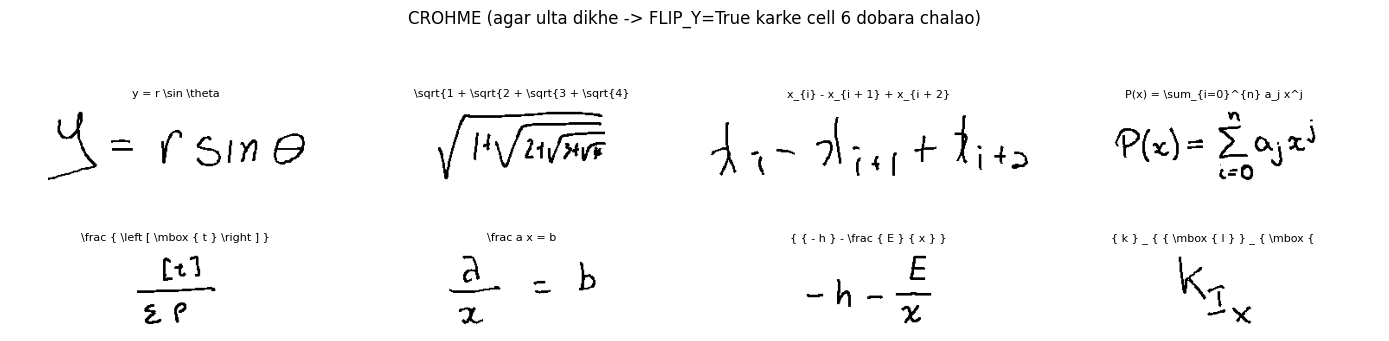

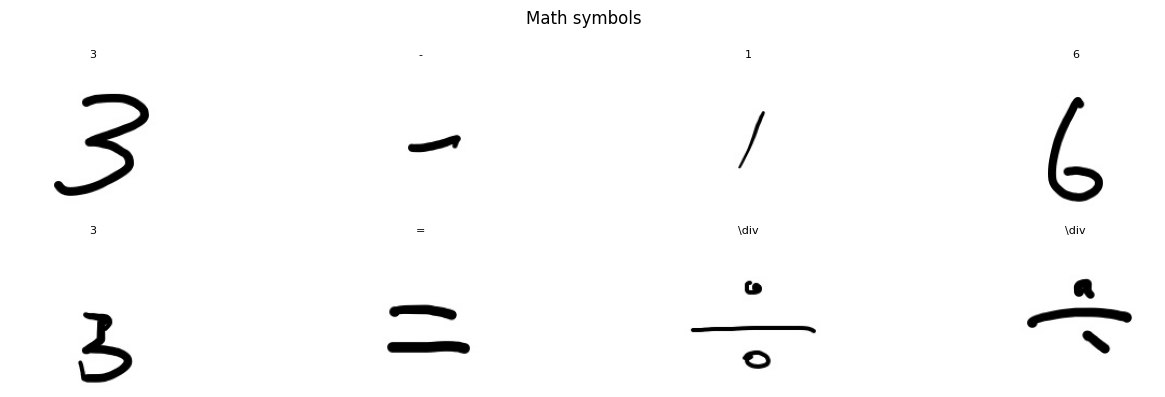

In [9]:
import csv, matplotlib.pyplot as plt
from PIL import Image

def preview(dir_: Path, n: int = 8, title: str = ""):
    rows = list(csv.DictReader(open(dir_ / "labels.csv", encoding="utf-8")))
    sample = random.Random(1).sample(rows, min(n, len(rows)))
    fig, axes = plt.subplots(2, 4, figsize=(14, 4))
    for ax, r in zip(axes.ravel(), sample):
        ax.imshow(Image.open(dir_ / "images" / r["filename"]), cmap="gray")
        ax.set_title(r["latex"][:38], fontsize=8); ax.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()

preview(crohme_out, title="CROHME (agar ulta dikhe -> FLIP_Y=True karke cell 6 dobara chalao)")
preview(symbols_out, title="Math symbols")

In [10]:
import logging
for noisy in ("httpx", "huggingface_hub", "httpcore"):
    logging.getLogger(noisy).setLevel(logging.WARNING)

import sentencepiece
print("sentencepiece", sentencepiece.__version__)

from transformers import TrOCRProcessor
from scripts.train_ocr import load_dataset_manifest, augment_image, compute_cer

random.seed(SEED)
import numpy as np; np.random.seed(SEED); torch.manual_seed(SEED)

def load_processor(name: str):
    try:
        return TrOCRProcessor.from_pretrained(name)
    except Exception as exc:  # noqa: BLE001
        print("TrOCRProcessor.from_pretrained fail:", repr(exc)[:200], "\n-> slow tokenizer fallback")
    from transformers import XLMRobertaTokenizer, AutoImageProcessor
    return TrOCRProcessor(image_processor=AutoImageProcessor.from_pretrained(name),
                          tokenizer=XLMRobertaTokenizer.from_pretrained(name))

processor = load_processor(BASE_MODEL)
tok = processor.tokenizer
tok.clean_up_tokenization_spaces = False   # LaTeX spacing decode me badle nahi
print("Tokenizer:", type(tok).__name__, "| vocab:", len(tok))

def load_items(dir_: Path, source: str):
    return [(p, latex, source) for p, latex in load_dataset_manifest(dir_)]

def split(items, seed=SEED):
    items = items[:]; random.Random(seed).shuffle(items)
    n = len(items); n_val = max(1, int(n * 0.05)); n_test = max(1, int(n * 0.05))
    return items[n_val + n_test:], items[:n_val], items[n_val:n_val + n_test]

tr_c, va_c, te_c = split(load_items(crohme_out, "crohme"))
tr_s, va_s, te_s = split(load_items(symbols_out, "symbols"))
train_items = tr_c + tr_s; val_items = va_c + va_s; test_items = te_c + te_s
random.Random(SEED).shuffle(train_items); random.Random(SEED).shuffle(val_items)

if SMOKE_TEST:
    train_items, val_items, test_items = train_items[:64], val_items[:16], test_items[:16]

# Tokenizer sanity: <unk> rate + decode roundtrip
enc = [tok(l).input_ids for _, l, _ in train_items]
lengths = [len(e) for e in enc]
unk_rate = float(np.mean([t == tok.unk_token_id for e in enc for t in e]))
rt_bad = sum(tok.decode(e, skip_special_tokens=True, clean_up_tokenization_spaces=False).strip() != l.strip()
             for e, (_, l, _) in zip(enc, train_items))
MAX_LEN = int(min(256, max(32, np.percentile(lengths, 99.5) + 8)))
print(f"train {len(train_items)} | val {len(val_items)} | test {len(test_items)}")
print(f"token length: mean {np.mean(lengths):.1f}, p99.5 {np.percentile(lengths, 99.5):.0f}, max {max(lengths)} -> MAX_LEN={MAX_LEN}")
print(f"<unk> token rate: {unk_rate:.4%} | decode-roundtrip mismatches: {rt_bad}/{len(train_items)}")
for e, (_, l, _) in list(zip(enc, train_items))[:3]:
    print("  ", repr(l[:40]), "->", repr(tok.decode(e, skip_special_tokens=True, clean_up_tokenization_spaces=False)[:40]))

sentencepiece 0.2.2


2026-10-18 22:15:48,512 | INFO     | numexpr.utils | NumExpr defaulting to 4 threads.


preprocessor_config.json:   0%|          | 0.00/224 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/772 [00:00<?, ?B/s]

Tokenizer: RobertaTokenizerFast | vocab: 50265


2026-10-18 22:15:55,524 | INFO     | scripts.train_ocr | Loaded 22021 samples from /kaggle/working/mathvision-ai/data/raw/crohme
2026-10-18 22:15:55,978 | INFO     | scripts.train_ocr | Loaded 2850 samples from /kaggle/working/mathvision-ai/data/raw/math_symbols


train 22385 | val 1243 | test 1243
token length: mean 18.3, p99.5 76, max 160 -> MAX_LEN=84
<unk> token rate: 0.0000% | decode-roundtrip mismatches: 0/22385
   'x^{2} + 2x + 1 = 0' -> 'x^{2} + 2x + 1 = 0'
   '{ \\gamma } _ { \\mbox { c } }' -> '{ \\gamma } _ { \\mbox { c } }'
   '\\frac { x } { a + \\frac { x } { b - \\fra' -> '\\frac { x } { a + \\frac { x } { b - \\fra'


In [7]:
import gc
for _n in ("trainer", "model"):
    if _n in globals(): globals()[_n] = None
sys.last_traceback = None; sys.last_value = None
gc.collect(); torch.cuda.empty_cache()
print("GPU0 free after cleanup: %.1f GB" % (torch.cuda.mem_get_info(0)[0] / 1e9))

GPU0 free after cleanup: 15.5 GB


In [11]:
import cv2
from PIL import Image
from torch.utils.data import Dataset
from transformers import (VisionEncoderDecoderModel, Seq2SeqTrainer, Seq2SeqTrainingArguments,
                          TrainerCallback)

class MathOCRDataset(Dataset):
    """(image, latex) pairs -> pixel_values + label ids (pad = -100)."""
    def __init__(self, items, augment: bool):
        self.items, self.augment = items, augment
        self.rng = random.Random(SEED)
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        path, latex, _ = self.items[i]
        img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
        if img is None:
            img = np.full((96, 384), 255, np.uint8)
        if self.augment:
            img = augment_image(img, self.rng)
        pv = processor(images=Image.fromarray(img).convert("RGB"), return_tensors="pt").pixel_values[0]
        ids = tok(latex, padding="max_length", max_length=MAX_LEN, truncation=True).input_ids
        ids = [t if t != tok.pad_token_id else -100 for t in ids]
        return {"pixel_values": pv, "labels": torch.tensor(ids)}

model = VisionEncoderDecoderModel.from_pretrained(BASE_MODEL).float()
model.config.decoder_start_token_id = tok.cls_token_id
model.config.pad_token_id = tok.pad_token_id
model.config.eos_token_id = tok.sep_token_id
model.config.vocab_size = model.config.decoder.vocab_size
gc = model.generation_config
gc.decoder_start_token_id, gc.pad_token_id, gc.eos_token_id = tok.cls_token_id, tok.pad_token_id, tok.sep_token_id
gc.max_length, gc.num_beams, gc.early_stopping, gc.no_repeat_ngram_size = MAX_LEN, 1, False, 0

n_gpu = max(1, torch.cuda.device_count())
ACCUM = max(1, EFFECTIVE_BATCH // (PER_DEVICE_BATCH * n_gpu))
GRAD_CKPT = not FAST_MODE
print(f"GPUs={n_gpu} | per-device batch={PER_DEVICE_BATCH} | grad_accum={ACCUM} | effective batch={PER_DEVICE_BATCH*n_gpu*ACCUM}")

def compute_metrics(pred):
    ids = pred.predictions[0] if isinstance(pred.predictions, tuple) else pred.predictions
    ids = np.where(ids < 0, tok.pad_token_id, ids)
    labels = np.where(pred.label_ids == -100, tok.pad_token_id, pred.label_ids)
    P = [s.strip() for s in tok.batch_decode(ids, skip_special_tokens=True, clean_up_tokenization_spaces=False)]
    R = [s.strip() for s in tok.batch_decode(labels, skip_special_tokens=True, clean_up_tokenization_spaces=False)]
    per = [compute_cer(p, r) for p, r in zip(P, R)]
    edits = sum(c * max(1, len(r)) for c, r in zip(per, R))
    return {"cer": float(edits / sum(max(1, len(r)) for r in R)),     # corpus CER (best-model metric)
            "cer_mean": float(np.mean(per)),                          # purana per-sample average
            "cer_median": float(np.median(per)),
            "exact_match": float(np.mean([p == r for p, r in zip(P, R)]))}

class TimeBudget(TrainerCallback):
    """Time budget khatam hone se pehle evaluate + save karke gracefully ruk jao."""
    def __init__(self, hours): self.deadline = time.time() + hours * 3600; self.hit = False
    def on_step_end(self, args, state, control, **kw):
        if time.time() > self.deadline:
            self.hit = True
            control.should_training_stop = True; control.should_evaluate = True; control.should_save = True

# transformers v4: warmup_ratio | v5: warmup_steps (float < 1 = ratio)
WARMUP = ({"warmup_ratio": 0.05} if "warmup_ratio" in Seq2SeqTrainingArguments.__dataclass_fields__
          else {"warmup_steps": 0.05})
CKPT_DIR = WORK / "ckpt"
budget = TimeBudget(TIME_BUDGET_HOURS)
args = Seq2SeqTrainingArguments(
    output_dir=str(CKPT_DIR),
    per_device_train_batch_size=PER_DEVICE_BATCH, per_device_eval_batch_size=4,   # eval bhi 8 -> 4
    gradient_accumulation_steps=ACCUM,
    num_train_epochs=1 if SMOKE_TEST else EPOCHS,
    learning_rate=LR, weight_decay=0.0, lr_scheduler_type="linear", max_grad_norm=1.0, **WARMUP,
    optim="adafactor",                      # <-- NEW: AdamW ke 4.5 GB states bachte hain
    fp16=True, gradient_checkpointing=GRAD_CKPT,
    eval_strategy="epoch", save_strategy="epoch", save_total_limit=2, save_only_model=True,
    load_best_model_at_end=True, metric_for_best_model="cer", greater_is_better=False,
    predict_with_generate=True, generation_max_length=MAX_LEN, generation_num_beams=1,
    logging_steps=10 if SMOKE_TEST else 50, report_to="none",
    dataloader_num_workers=2, remove_unused_columns=False, seed=SEED,
)
trainer = Seq2SeqTrainer(
    model=model, args=args,
    train_dataset=MathOCRDataset(train_items, augment=True),
    eval_dataset=MathOCRDataset(val_items[:EVAL_SUBSET], augment=False),
    compute_metrics=compute_metrics, callbacks=[budget],
)

2026-10-18 22:16:49,476 | INFO     | datasets | TensorFlow version 2.20.0 available.
2026-10-18 22:16:49,478 | INFO     | datasets | JAX version 0.11.1 available.


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/2.23G [00:00<?, ?B/s]

Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-large-handwritten and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


generation_config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

GPUs=1 | per-device batch=2 | grad_accum=4 | effective batch=8


model.safetensors:   0%|          | 0.00/2.23G [00:00<?, ?B/s]

In [9]:
import time
print("CPU cores:", os.cpu_count(), "| MAX_LEN:", MAX_LEN, "| train samples:", len(train_items))

# 1) data loading kitna slow hai?
ds = MathOCRDataset(train_items[:16], augment=True)
t = time.time(); batch = [ds[i] for i in range(8)]; print("data load, 8 samples: %.2fs" % (time.time() - t))
print("sample image shape:", cv2.imread(str(train_items[0][0]), 0).shape)

# 2) GPU compute kitna slow hai? (single GPU, batch 2, forward+backward)
m = trainer.model.module if hasattr(trainer.model, "module") else trainer.model
m.to("cuda:0").train()
pv = torch.stack([b["pixel_values"] for b in batch[:2]]).to("cuda:0")
lb = torch.stack([b["labels"] for b in batch[:2]]).to("cuda:0")
torch.cuda.reset_peak_memory_stats()
for i in range(3):
    torch.cuda.synchronize(); t = time.time()
    with torch.autocast("cuda", dtype=torch.float16):
        loss = m(pixel_values=pv, labels=lb).loss
    loss.backward(); m.zero_grad(set_to_none=True)
    torch.cuda.synchronize(); print(f"fwd+bwd batch=2: {time.time()-t:.2f}s")
st = torch.cuda.memory_stats(0)
print("alloc retries:", st.get("num_alloc_retries"), "| peak mem GB: %.1f" % (torch.cuda.max_memory_allocated(0) / 1e9))

trainer.save_model(str(WORK / "best_model")); processor.save_pretrained(str(WORK / "best_model"))
print("Saved best model ->", WORK / "best_model")

CPU cores: 4 | MAX_LEN: 84 | train samples: 22385
data load, 8 samples: 0.31s
sample image shape: (96, 384)


`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


fwd+bwd batch=2: 12.10s
fwd+bwd batch=2: 0.20s
fwd+bwd batch=2: 0.21s
alloc retries: 0 | peak mem GB: 5.3
Saved best model -> /kaggle/working/best_model


In [10]:
t0 = time.time()
torch.cuda.reset_peak_memory_stats()
train_result = trainer.train()
train_hours = (time.time() - t0) / 3600
print(f"\nTraining time: {train_hours:.2f} h | peak GPU0 memory: {torch.cuda.max_memory_allocated()/1e9:.1f} GB")
if budget.hit:
    print("WARNING: time budget hit — training epochs poore hone se pehle roka gaya (best checkpoint load hua).")
history = [h for h in trainer.state.log_history if "eval_cer" in h]
for h in history:
    print(f"epoch {h['epoch']:.2f}: eval_cer={h['eval_cer']:.4f} exact={h['eval_exact_match']:.3f}")

Epoch,Training Loss,Validation Loss,Cer,Cer Mean,Cer Median,Exact Match
1,0.509400,0.575447,1.738819,1.653520,0.823985,0.098000
2,0.323700,0.258184,1.370662,1.251762,0.606061,0.100000
3,0.164600,0.141115,1.219893,1.177224,0.600000,0.098000
4,0.055000,0.085377,1.157066,1.071811,0.583333,0.102000


There were missing keys in the checkpoint model loaded: ['decoder.output_projection.weight'].



Training time: 5.74 h | peak GPU0 memory: 5.9 GB
epoch 1.00: eval_cer=1.7388 exact=0.098
epoch 2.00: eval_cer=1.3707 exact=0.100
epoch 3.00: eval_cer=1.2199 exact=0.098
epoch 4.00: eval_cer=1.1571 exact=0.102


In [12]:
from safetensors.torch import load_file
ck = WORK / "ckpt" / "checkpoint-11196"
sd = load_file(str(ck / "model.safetensors"))
res = trainer.model.load_state_dict(sd, strict=False)
print("missing:", res.missing_keys, "| unexpected:", res.unexpected_keys[:5])
trainer.save_model(str(WORK / "best_model"))
processor.save_pretrained(str(WORK / "best_model"))
print(os.popen(f"du -sh {WORK / 'best_model'}").read())

missing: ['decoder.output_projection.weight'] | unexpected: []
2.1G	/kaggle/working/best_model



{
  "overall": {
    "n": 1243,
    "cer": 0.8857684055972697,
    "exact_match": 0.1166532582461786
  },
  "crohme": {
    "n": 1101,
    "cer": 0.9897912154018221,
    "exact_match": 0.015440508628519528
  },
  "symbols": {
    "n": 142,
    "cer": 0.07922535211267606,
    "exact_match": 0.9014084507042254
  }
}

Target CER < 0.08 -> NOT MET (actual number hi README me likho)


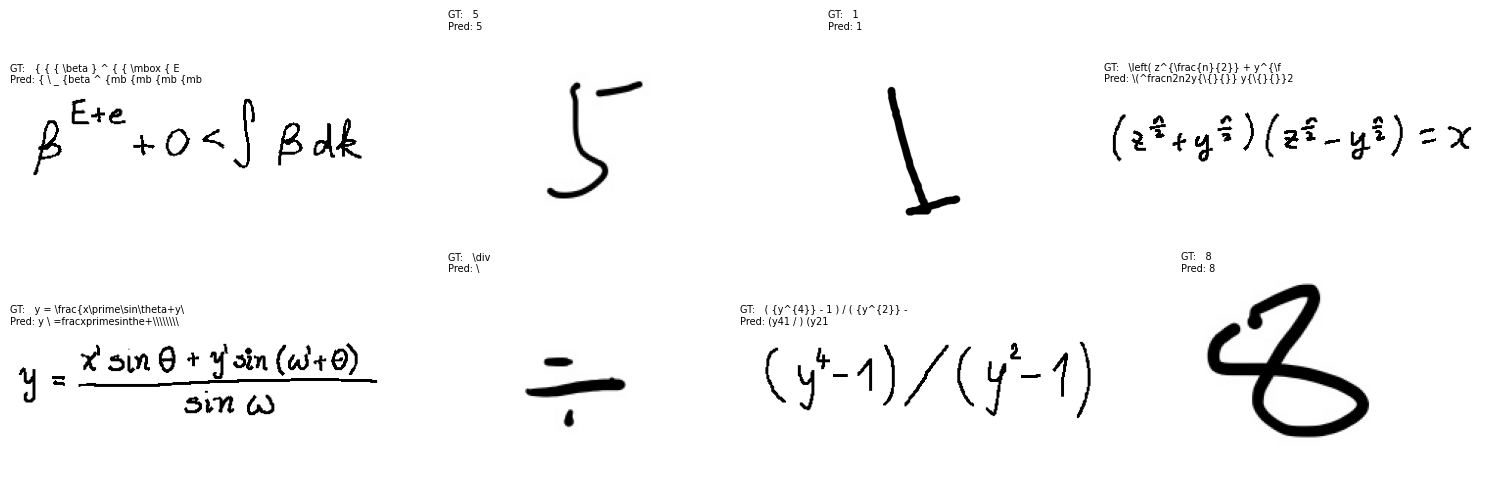

In [13]:
device = torch.device("cuda:0")
model = trainer.model
if hasattr(model, "gradient_checkpointing_disable"):
    model.gradient_checkpointing_disable()
model.config.use_cache = True
model.to(device).eval()

@torch.no_grad()
def predict_items(items, num_beams=4, bs=8):
    ds = MathOCRDataset(items, augment=False); preds = []
    for i in range(0, len(items), bs):
        pv = torch.stack([ds[j]["pixel_values"] for j in range(i, min(i + bs, len(items)))]).to(device)
        with torch.autocast("cuda", dtype=torch.float16):
            out = model.generate(pv, max_length=MAX_LEN, num_beams=num_beams)
        preds += [s.strip() for s in tok.batch_decode(out, skip_special_tokens=True, clean_up_tokenization_spaces=False)]
    return preds

def score(items, preds):
    refs = [l.strip() for _, l, _ in items]
    cers = [compute_cer(p, r) for p, r in zip(preds, refs)]
    return {"n": len(items), "cer": float(np.mean(cers)), "exact_match": float(np.mean([p == r for p, r in zip(preds, refs)]))}

test_preds = predict_items(test_items)
results = {"overall": score(test_items, test_preds)}
for src in ("crohme", "symbols"):
    idx = [i for i, it in enumerate(test_items) if it[2] == src]
    if idx:
        results[src] = score([test_items[i] for i in idx], [test_preds[i] for i in idx])

print(json.dumps(results, indent=2))
print("\nTarget CER < 0.08 ->", "MET" if results["overall"]["cer"] < 0.08 else "NOT MET (actual number hi README me likho)")

fig, axes = plt.subplots(2, 4, figsize=(15, 5))
for ax, i in zip(axes.ravel(), random.Random(3).sample(range(len(test_items)), min(8, len(test_items)))):
    ax.imshow(Image.open(test_items[i][0]), cmap="gray"); ax.axis("off")
    ax.set_title(f"GT:   {test_items[i][1][:30]}\nPred: {test_preds[i][:30]}", fontsize=7, loc="left")
plt.tight_layout(); plt.show()

crohme   n=1101 corpus CER = 1.000
symbols  n= 142 corpus CER = 0.297

GT  : x = r \cos \theta
PRED: x rcosthe

GT  : \int \left( 2^{x} - 3 e^{x} \right) d x
PRED: \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ 

GT  : p^{\beta-\alpha}
PRED: p{\-alpha

GT  : \cos \alpha = \frac{a}{\sqrt{a^2 + b^2 + c^2}}
PRED: \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ 

GT  : -2x
PRED: -x

GT  : \left ( { \mbox { G } - \mbox { V } } \right )
PRED: \ ( \ox G \ox V \ )

GT  : [ b^x \{ ( \frac a b )^x + 1 \} ]^{\frac 1 x}
PRED: [ bx{ \ (frac b^ + \ )x 1}^frac x

GT  : \begin {pmatrix} 3 & 4 \\ 1 & 2 \end {pmatrix} \begin {pmatrix} 1 & - 
PRED: \ {} 3 4 1 2 \ { }right \ {}beginpmrix 1 - \\ 1 3 \ { 1 3 \ {}endpmrix

GT  : \frac 2 {\frac {3 m - 2 n \times 9^n - 9^m} {2 n - 1}}
PRED: \ 2frac3 - n 2 \ 9ntimes^ -^}2 -^ -^ -^ -^ -^in 1

GT  : x_1 \times x_2 \times x_3 \times x_4 = X
PRED: x1times_ \ x2times_ \ x3times_ =

GT  : a_{n} = a_{1} \cdot {q^{n - 1}}
PR

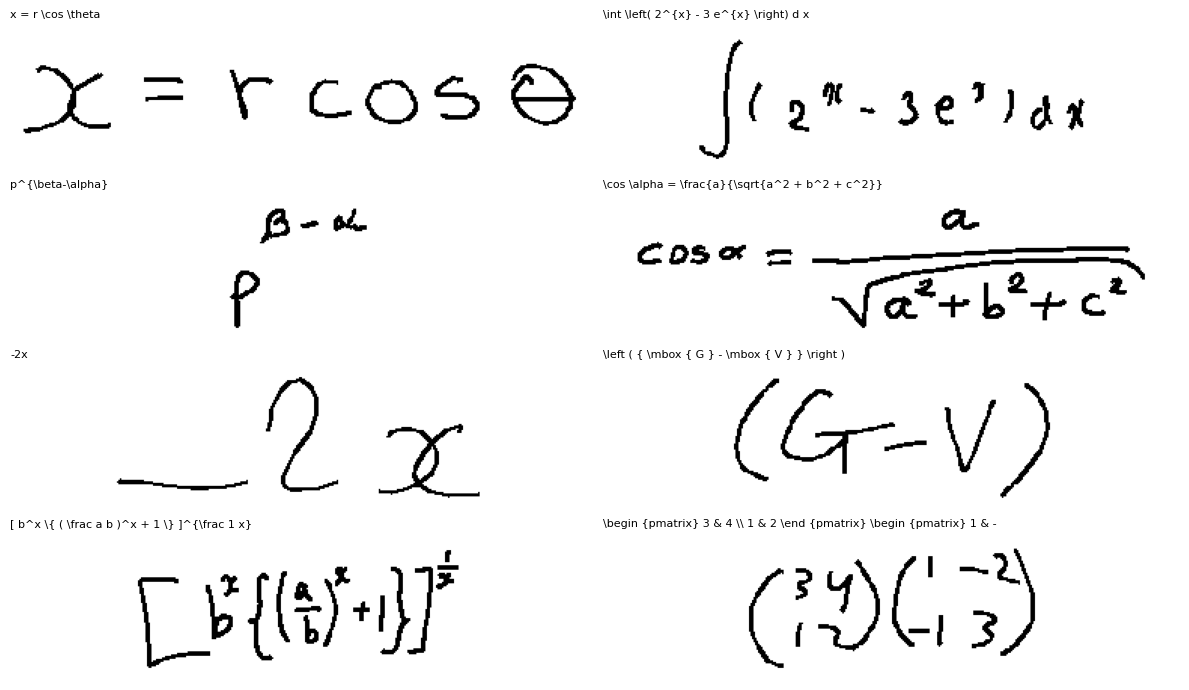

BLANK image preds: ['\\ox', '\\ox', '\\ox', '\\ox']


In [14]:
cro_idx = [i for i, it in enumerate(test_items) if it[2] == "crohme"]
sym_idx = [i for i, it in enumerate(test_items) if it[2] == "symbols"]

for name, ii in (("crohme", cro_idx), ("symbols", sym_idx)):
    refs_ = [test_items[i][1].strip() for i in ii]
    tot_ = sum(compute_cer(test_preds[i], r) * max(1, len(r)) for i, r in zip(ii, refs_))
    print(f"{name:8} n={len(ii):4} corpus CER = {tot_ / sum(max(1, len(r)) for r in refs_):.3f}")

print()
for i in cro_idx[:12]:
    print("GT  :", test_items[i][1][:70]); print("PRED:", test_preds[i][:70]); print()

fig, axes = plt.subplots(4, 2, figsize=(12, 7))
for ax, i in zip(axes.ravel(), cro_idx[:8]):
    ax.imshow(Image.open(test_items[i][0]), cmap="gray"); ax.axis("off")
    ax.set_title(test_items[i][1][:70], fontsize=8, loc="left")
plt.tight_layout(); plt.show()

blank = Image.fromarray(np.full((96, 384), 255, np.uint8)).convert("RGB")
pv = processor(images=[blank] * 4, return_tensors="pt").pixel_values.to(device)
with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
    out = model.generate(pv, max_length=MAX_LEN, num_beams=4)
print("BLANK image preds:", tok.batch_decode(out, skip_special_tokens=True))

In [15]:
sub = [it for it in test_items if it[2] == "crohme"][:32]
ds = MathOCRDataset(sub, augment=False)
pv = torch.stack([ds[i]["pixel_values"] for i in range(len(sub))]).to(device)
lb = torch.stack([ds[i]["labels"] for i in range(len(sub))]).to(device)
refs_ = [it[1].strip() for it in sub]

def cer_of(preds):
    t = sum(compute_cer(p, r) * max(1, len(r)) for p, r in zip(preds, refs_))
    return t / sum(max(1, len(r)) for r in refs_)

model.eval()
with torch.no_grad():
    # A) teacher-forced argmax: model sahi pichla text mile to kitna sahi bolta hai?
    with torch.autocast("cuda", dtype=torch.float16):
        logits = model(pixel_values=pv[:16], labels=lb[:16]).logits
    am = logits.argmax(-1).cpu(); keep = (lb[:16].cpu() != -100)
    am = torch.where(keep, am, torch.full_like(am, tok.pad_token_id))
    tf = [s.strip() for s in tok.batch_decode(am, skip_special_tokens=True, clean_up_tokenization_spaces=False)]
    t = sum(compute_cer(p, r) * max(1, len(r)) for p, r in zip(tf, refs_[:16]))
    print("A) teacher-forced CER: %.3f" % (t / sum(max(1, len(r)) for r in refs_[:16])))
    print("   GT  :", refs_[1][:60], "\n   PRED:", tf[1][:60])

    # B) generation: cache ON vs OFF
    for uc in (True, False):
        preds = []
        for i in range(0, len(sub), 16):
            with torch.autocast("cuda", dtype=torch.float16):
                out = model.generate(pv[i:i+16], max_length=MAX_LEN, num_beams=1, use_cache=uc)
            preds += [s.strip() for s in tok.batch_decode(out, skip_special_tokens=True, clean_up_tokenization_spaces=False)]
        print(f"B) generate use_cache={uc}: CER {cer_of(preds):.3f}")
        print("   GT  :", refs_[1][:60], "\n   PRED:", preds[1][:60])

`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


A) teacher-forced CER: 0.007
   GT  : \int \left( 2^{x} - 3 e^{x} \right) d x 
   PRED: \int \left( 2^{x} - 3 e^{x} \right) d x
B) generate use_cache=True: CER 0.824
   GT  : \int \left( 2^{x} - 3 e^{x} \right) d x 
   PRED: \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ 
B) generate use_cache=False: CER 0.824
   GT  : \int \left( 2^{x} - 3 e^{x} \right) d x 
   PRED: \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ 


In [16]:
print("start ids  cfg:", model.config.decoder_start_token_id, "| gen:", model.generation_config.decoder_start_token_id,
      "| eos:", model.generation_config.eos_token_id, "| pad:", model.generation_config.pad_token_id)
print(model.generation_config)
print("label first ids:", lb[1][:8].tolist())

# Manual greedy decoding (generate() ke bina)
N = 16
with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
    enc = model.encoder(pixel_values=pv[:N]).last_hidden_state
    ids = torch.full((N, 1), model.config.decoder_start_token_id, device=device, dtype=torch.long)
    for _ in range(MAX_LEN - 1):
        logits = model(encoder_outputs=(enc,), decoder_input_ids=ids).logits[:, -1]
        ids = torch.cat([ids, logits.argmax(-1, keepdim=True)], 1)
        if ((ids == tok.sep_token_id).any(1)).all(): break
man = [s.strip() for s in tok.batch_decode(ids[:, 1:], skip_special_tokens=True, clean_up_tokenization_spaces=False)]
t = sum(compute_cer(p, r) * max(1, len(r)) for p, r in zip(man, refs_[:N]))
print("C) manual greedy CER: %.3f" % (t / sum(max(1, len(r)) for r in refs_[:N])))
print("   manual ids[1]:", ids[1, :8].tolist())
for i in (0, 1, 2, 4):
    print("   GT  :", refs_[i][:60], "\n   PRED:", man[i][:60])

with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
    g = model.generate(pv[:N], max_length=MAX_LEN, num_beams=1)
print("   generate ids[1]:", g[1, :8].tolist())

start ids  cfg: 0 | gen: 0 | eos: 2 | pad: 1
GenerationConfig {
  "bos_token_id": 0,
  "decoder_start_token_id": 0,
  "eos_token_id": 2,
  "max_length": 84,
  "pad_token_id": 1,
  "use_cache": false
}

label first ids: [0, 37457, 2544, 44128, 6960, 1640, 132, 49688]
C) manual greedy CER: 1.485
   manual ids[1]: [0, 37457, 44128, 44128, 44128, 44128, 44128, 44128]
   GT  : x = r \cos \theta 
   PRED: x rcosthethethethethethethe
   GT  : \int \left( 2^{x} - 3 e^{x} \right) d x 
   PRED: \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ 
   GT  : p^{\beta-\alpha} 
   PRED: p{\-alphabetaalphaalphaalphaalphaalphaalphaalphaalphaalphaal
   GT  : -2x 
   PRED: -x
   generate ids[1]: [0, 37457, 44128, 44128, 44128, 44128, 44128, 44128]


In [17]:
N = 16
pre = torch.full((N, 2), tok.cls_token_id, dtype=torch.long, device=device)   # [<s>, <s>] = training wala decoder input
with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
    g = model.generate(pv[:N], decoder_input_ids=pre, max_length=MAX_LEN, num_beams=1)
fix = [s.strip() for s in tok.batch_decode(g, skip_special_tokens=True, clean_up_tokenization_spaces=False)]
t = sum(compute_cer(p, r) * max(1, len(r)) for p, r in zip(fix, refs_[:N]))
cer_fix = t / sum(max(1, len(r)) for r in refs_[:N])
print("D) generate + [<s>,<s>] prefix CER: %.3f" % cer_fix)
for i in (0, 1, 2, 4, 6):
    print("   GT  :", refs_[i][:60], "\n   PRED:", fix[i][:60])

# Agar fix chala (CER < 0.3), to poore test set par beam search ke saath score karo
if cer_fix < 0.3:
    @torch.no_grad()
    def predict_fixed(items, num_beams=4, bs=16):
        ds = MathOCRDataset(items, augment=False); out_ = []
        for i in range(0, len(items), bs):
            j = range(i, min(i + bs, len(items)))
            pv_ = torch.stack([ds[k]["pixel_values"] for k in j]).to(device)
            pre_ = torch.full((len(j), 2), tok.cls_token_id, dtype=torch.long, device=device)
            with torch.autocast("cuda", dtype=torch.float16):
                o = model.generate(pv_, decoder_input_ids=pre_, max_length=MAX_LEN, num_beams=num_beams)
            out_ += [s.strip() for s in tok.batch_decode(o, skip_special_tokens=True, clean_up_tokenization_spaces=False)]
        return out_

    test_preds = predict_fixed(test_items)
    for name in ("crohme", "symbols", None):
        ii = [i for i, it in enumerate(test_items) if name is None or it[2] == name]
        rr = [test_items[i][1].strip() for i in ii]
        tt = sum(compute_cer(test_preds[i], r) * max(1, len(r)) for i, r in zip(ii, rr))
        em = np.mean([test_preds[i] == r for i, r in zip(ii, rr)])
        print(f"{name or 'overall':8} n={len(ii):4} corpus CER = {tt / sum(max(1, len(r)) for r in rr):.3f} | exact = {em:.3f}")

D) generate + [<s>,<s>] prefix CER: 0.906
   GT  : x = r \cos \theta 
   PRED: = \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ 
   GT  : \int \left( 2^{x} - 3 e^{x} \right) d x 
   PRED: intleft 2x 3^{}^{}^{}^{}^{}^{}^{}^{}^{}^{}^{}^{}^{}^{}^{}^{}
   GT  : p^{\beta-\alpha} 
   PRED: ^beta{\-alpha
   GT  : -2x 
   PRED: 2
   GT  : [ b^x \{ ( \frac a b )^x + 1 \} ]^{\frac 1 x} 
   PRED: bx{ \ (frac b^ + \ )x 1}^frac x


In [18]:
import shutil
shutil.make_archive(str(WORK / "trained_model_epoch4"), "zip", str(WORK / "best_model"))
print(os.popen(f"ls -lh {WORK}/trained_model_epoch4.zip").read())

-rw-r--r-- 1 root root 2.0G Oct 18 23:15 /kaggle/working/trained_model_epoch4.zip



In [19]:
@torch.no_grad()
def decode_shifted(pixel_values, max_len=MAX_LEN):
    """Double-shift model ke liye: P[k] = token k+1; decoder input = [<s>, <s>, P0, P1, ...]"""
    N = pixel_values.size(0); S = tok.cls_token_id; EOS = tok.sep_token_id
    dev = pixel_values.device
    with torch.autocast("cuda", dtype=torch.float16):
        enc = model.encoder(pixel_values=pixel_values).last_hidden_state
        P = []
        for k in range(max_len):
            if k == 0:
                D = torch.full((N, 1), S, dtype=torch.long, device=dev)
            else:
                D = torch.cat([torch.full((N, 2), S, dtype=torch.long, device=dev)] + [p[:, None] for p in P[:k - 1]], 1)
            P.append(model(encoder_outputs=(enc,), decoder_input_ids=D).logits[:, -1].argmax(-1))
            if k > 0 and (torch.stack(P, 1) == EOS).any(1).all():
                break
    out = []
    for row in torch.stack(P, 1).tolist():
        if EOS in row: row = row[:row.index(EOS)]
        out.append(tok.decode(row, skip_special_tokens=True, clean_up_tokenization_spaces=False).strip())
    return out

N = 16
e = decode_shifted(pv[:N])
t = sum(compute_cer(p, r) * max(1, len(r)) for p, r in zip(e, refs_[:N]))
cer_e = t / sum(max(1, len(r)) for r in refs_[:N])
print("E) shifted decoding CER: %.3f" % cer_e)
for i in (0, 1, 2, 4, 6):
    print("   GT  :", refs_[i][:60], "\n   PRED:", e[i][:60])

if cer_e < 0.3:
    ds_all = MathOCRDataset(test_items, augment=False); test_preds = []
    for i in range(0, len(test_items), 16):
        j = range(i, min(i + 16, len(test_items)))
        test_preds += decode_shifted(torch.stack([ds_all[k]["pixel_values"] for k in j]).to(device))
    for name in ("crohme", "symbols", None):
        ii = [i for i, it in enumerate(test_items) if name is None or it[2] == name]
        rr = [test_items[i][1].strip() for i in ii]
        tt = sum(compute_cer(test_preds[i], r) * max(1, len(r)) for i, r in zip(ii, rr))
        em = np.mean([test_preds[i] == r for i, r in zip(ii, rr)])
        print(f"{name or 'overall':8} n={len(ii):4} corpus CER = {tt / sum(max(1, len(r)) for r in rr):.3f} | exact = {em:.3f}")

E) shifted decoding CER: 0.030
   GT  : x = r \cos \theta 
   PRED: x = r \cos \theta
   GT  : \int \left( 2^{x} - 3 e^{x} \right) d x 
   PRED: \int \left( 2^{x} - 3 e^{x} \right) d x
   GT  : p^{\beta-\alpha} 
   PRED: p^{\beta-\alpha}
   GT  : -2x 
   PRED: -2x
   GT  : [ b^x \{ ( \frac a b )^x + 1 \} ]^{\frac 1 x} 
   PRED: [ b^x \{ ( \frac a b )^x + 1 \} ]^{\frac 1 x}
crohme   n=1101 corpus CER = 0.139 | exact = 0.798
symbols  n= 142 corpus CER = 0.000 | exact = 1.000
overall  n=1243 corpus CER = 0.138 | exact = 0.821


In [20]:
import json
(WORK / "best_model" / "decoding.json").write_text(json.dumps({
    "double_shift": True,
    "note": "Trained with double label shift. Decoder input = [<s>, <s>, P0, P1, ...], P[k] = token k+1. Plain generate() fails."}, indent=2))
card = {"base_model": BASE_MODEL, "epochs": 4, "train_samples": len(train_items), "train_hours": 5.74,
        "decoding": "greedy, shifted (see decoding.json)",
        "test": {"n": 1243, "corpus_cer": 0.138, "exact_match": 0.821,
                 "crohme": {"n": 1101, "corpus_cer": 0.139, "exact_match": 0.798},
                 "symbols": {"n": 142, "corpus_cer": 0.0, "exact_match": 1.0}},
        "caveat": "CROHME has duplicate expressions across years; random split may inflate exact match."}
for p in (WORK / "best_model" / "model_card.json", WORK / "model_card.json"):
    p.write_text(json.dumps(card, indent=2))
print("ok")

ok


In [21]:
import shutil
shutil.make_archive(str(WORK / "trained_model_epoch4"), "zip", str(WORK / "best_model"))
print(os.popen(f"ls -lh {WORK}/trained_model_epoch4.zip").read())

-rw-r--r-- 1 root root 2.0G Oct 18 23:31 /kaggle/working/trained_model_epoch4.zip



In [23]:
from huggingface_hub import HfApi

REPO_ID = "narendrakalam2001/trocr-math-ep4"
api = HfApi(token="hf_Lk**********")        # yahan apna asli token (ya neeche wala Secrets tareeka)
api.create_repo(REPO_ID, private=True, exist_ok=True)
api.upload_folder(folder_path=str(WORK / "best_model"), repo_id=REPO_ID)
print("Uploaded: https://huggingface.co/" + REPO_ID)

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Uploaded: https://huggingface.co/narendrakalam2001/trocr-math-ep4


In [24]:
print(os.popen("unzip -l /kaggle/working/trained_model_epoch4.zip").read())

Archive:  /kaggle/working/trained_model_epoch4.zip
  Length      Date    Time    Name
---------  ---------- -----   ----
   456318  2026-10-18 22:18   merges.txt
      205  2026-10-18 22:18   generation_config.json
     1284  2026-10-18 22:18   tokenizer_config.json
      155  2026-10-18 23:28   decoding.json
  3558642  2026-10-18 22:18   tokenizer.json
      538  2026-10-18 23:28   model_card.json
     1508  2026-10-18 22:18   config.json
      957  2026-10-18 22:18   special_tokens_map.json
   798293  2026-10-18 22:18   vocab.json
      390  2026-10-18 22:18   preprocessor_config.json
     5969  2026-10-18 22:18   training_args.bin
2232985336  2026-10-18 22:18   model.safetensors
---------                     -------
2237809595                     12 files



## Ab kya karna hai
1. Right panel -> **Output** se `trocr_finetuned.zip` aur `model_card.json` download karo.
2. Local project me `models/trocr_finetuned/` me zip extract karo, `model_card.json` ko `models/` me rakho.
3. Local `.env` me: `TROCR_BASE_MODEL=<absolute path>/models/trocr_finetuned`
4. Phir local pe API / Streamlit app / tests chalao.